**Overview:** Our proposal seeks to investigate the impact of data centers on countries around the world, as well as how the economic status of those countries might impact the role of data centers. The primary data set that we have chosen contains a list of countries with affiliated metrics, such as total carbon footprint, number of data centers within a given country, and different classifications of data centers. We plan to merge this data set with longitudinal data describing the unemployment rates of the same countries over the past several years, intending to investigate the role of data centers in the livelihood of citizens of different countries. 


**PJ**

**Question 1:** Can the number of data centers in a country be positively correlated with economic status? How does data centers per capita reflect GDP? 


**Variables:** country, obs_val, age , osm_facilities, but we will need GDP to correlate with these variables, which will involve merging with another data set

**Description:** The number of data centers in a country likely has an impact on the economy of that country, which might be correlated with an improvement in GDP. Though this relationship is probably not totally causal, it would be interesting to investigate how data centers affect local economies. As a future analysis, we will explore if data centers act as a good predictor for other things about those countries (population, democracy-status, GDP, etc.). The likely hypothesis, given the boom of AI and other data-driven industries, is that countries tend to have higher GDPs as they have more data centers. 


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/country_summary.csv")
df.describe


<bound method NDFrame.describe of                          country country_iso2 country_iso3      continent  \
0       United States of America           US          USA  North America   
1                         France           FR          FRA         Europe   
2                        Germany           DE          DEU         Europe   
3                 United Kingdom           GB          GBR         Europe   
4                    Netherlands           NL          NLD         Europe   
..                           ...          ...          ...            ...   
111          Trinidad and Tobago           TT          TTO  North America   
112                      Tunisia           TN          TUN         Africa   
113                       Tuvalu           TV          TUV        Oceania   
114  United Republic of Tanzania           TZ          TZA         Africa   
115                   Uzbekistan           UZ          UZB           Asia   

            subregion  osm_facilities  wi

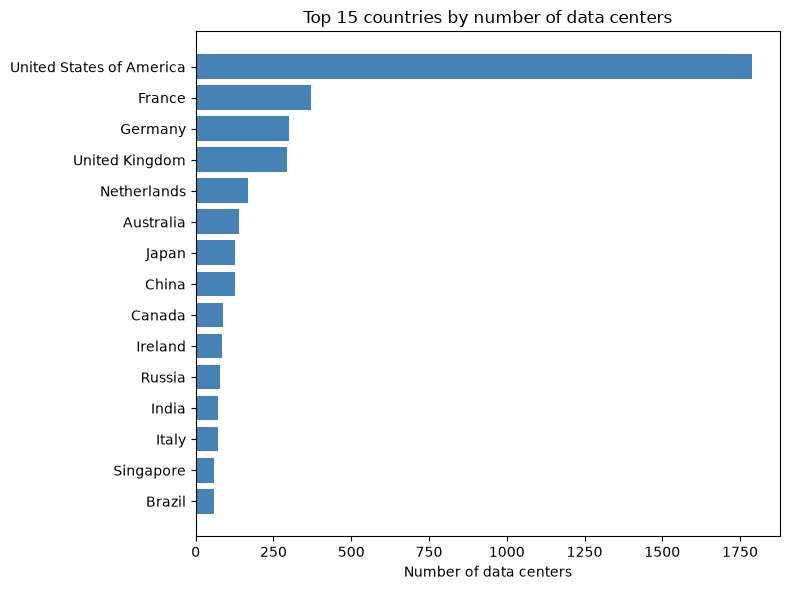

In [2]:
# top 15 counteries datacenters
top = df.nlargest(15, "osm_facilities").sort_values("osm_facilities")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["country"], top["osm_facilities"], color="steelblue")
ax.set_xlabel("Number of data centers")
ax.set_title("Top 15 countries by number of data centers")
plt.tight_layout()
plt.show()

This graph shows the number of data centers in each country. The United States has signficiantly more than any other country.

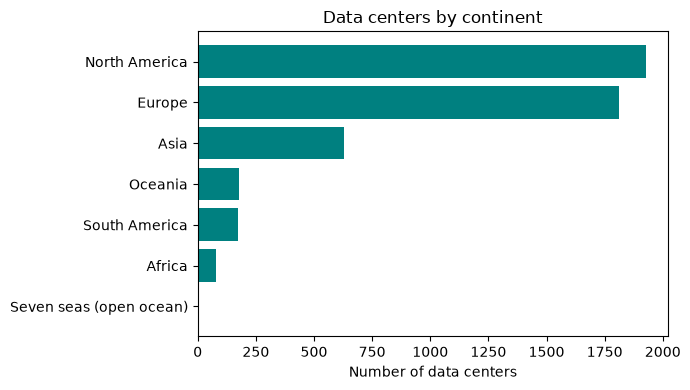

In [3]:
# by continent
by_continent = (
    df.groupby("continent", as_index=False)["osm_facilities"]
    .sum()
    .sort_values("osm_facilities")
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_continent["continent"], by_continent["osm_facilities"], color="teal")
ax.set_xlabel("Number of data centers")
ax.set_title("Data centers by continent")
plt.tight_layout()
plt.show()

This figure demonstrates that North America and Europe have the most data centers. Though America has substantially more than other countries, Europe on the whole has almost as many. 

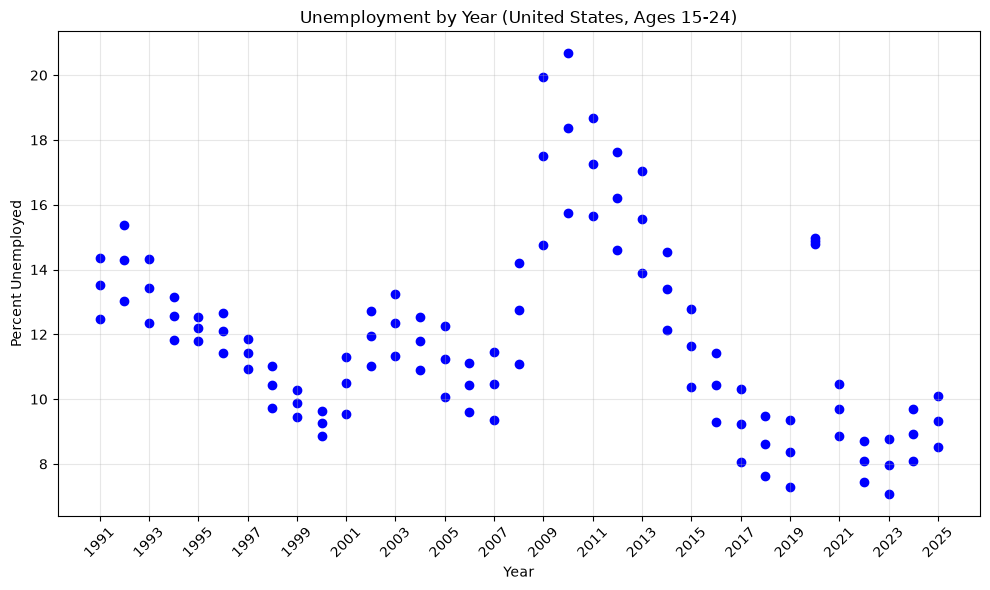

In [4]:
unemployed = pd.read_csv("dataset/disoccupazione.csv")
us_young = unemployed[(unemployed['iso_code'] == 'USA') & (unemployed['age'] == '15-24')]

plt.figure(figsize=(10, 6))

plt.scatter(us_young['year'], us_young['obs_value'], color='blue')

# Add labels and title
plt.xlabel('Year')
plt.ylabel('Percent Unemployed')
plt.title('Unemployment by Year (United States, Ages 15-24)')

plt.grid(True, alpha=0.3)
plt.xticks(
    sorted(us_young['year'].unique())[::2],
    rotation=45
)

plt.tight_layout()
plt.show()

plt.show()

This graph shows unemployment by year in the US from ages 15-24. Note the spike during the recession.

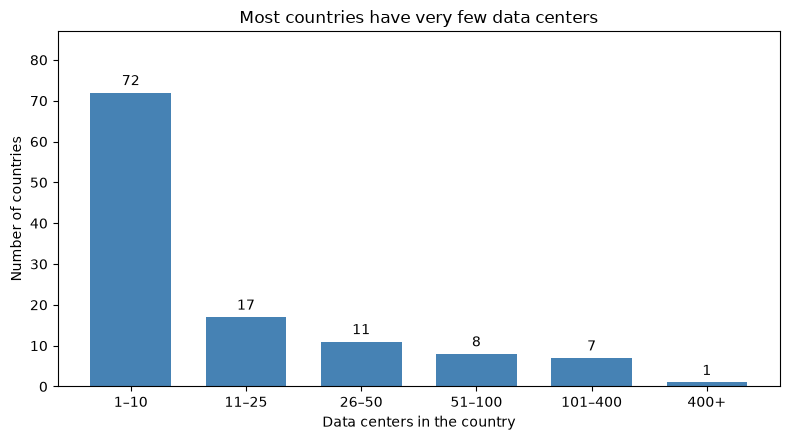

In [7]:
bins = [0, 10, 25, 50, 100, 400, df["osm_facilities"].max()]
labels = ["1–10", "11–25", "26–50", "51–100", "101–400", "400+"]
df["count_group"] = pd.cut(df["osm_facilities"], bins=bins, labels=labels)

counts = df["count_group"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index.astype(str), counts.values, color="steelblue", width=0.7)
ax.bar_label(bars, padding=3)
ax.set_xlabel("Data centers in the country")
ax.set_ylabel("Number of countries")
ax.set_title("Most countries have very few data centers")
ax.set_ylim(0, counts.max() + 15)
plt.tight_layout()
plt.show()

Most countries have only 1-10 data centers.

**The Plan and Considerations**

Of course, this preliminary data visualization only gives some insight into the question. We would still need another data set in order to manipulate the GDP variable. 
One option would be to merge a longitudinal data set of GDP onto the longitudinal data set of unemployment rates per country.
An interesting related idea would be seeing how data centers affect unemployment in certain age demographics, 
potentially weighting with GDP. This data already exists in part in our unemployment data set. 
Similarly, population is not part of the data set, so we might search for one that contains both population and GDP.

**Lukas**

**Question 2:** : How does the number of data centers in a country correlate to carbon footprint? Which countries have the most footprint per data center, and why?


**Variables that Answer**

Answered in part by osm_facilities, median_footprint_m2, and total_footprint_m2, but will need to estimate in part the carbon foorprint by constructing via the total footprint and an assumed grid intensity value, unless there is a concrete measurement out there. 

**Preparation**

We already have the footprint and first looks for most countries and continents broadly. We will need to erase or substitute some of the footprint measurements, since some of the facilities are point mapped rather than actually measured out. Also, some of the sizes look to be too small to be correct, so we may have to drop some of those as well, depending on what is actually plausible. Some na=false commands and editing of codes that don't directly map or match to anything will be required.

**Description:** Another pressing issue concerning data centers is their environmental impact, often measured using carbon footprint. Our data set describes the carbon footprint of each of these countries, which seems like it would be positively correlated with the number of data centers. However, because we do not know the exact size of these data centers, the results might deviate from our expectations (for instance, larger data centers present in a smaller number might produce a greater carbon footprint). We intend to create a variable that measures the footprint per data center and investigate which countries lead the category. 



In [5]:
# join datasets and clean
centers = pd.read_csv("dataset/country_summary.csv")
carbon = pd.read_csv("K Dataset/ember carbon intensity.csv")

df = centers.merge(
    carbon[["country_iso3", "emissions_mtco2e", "emissions_intensity_gco2e_per_kwh"]],
    on="country_iso3",
    how="inner",
)

df["avg_footprint_m2"] = df["total_footprint_m2"] / df["osm_facilities"]

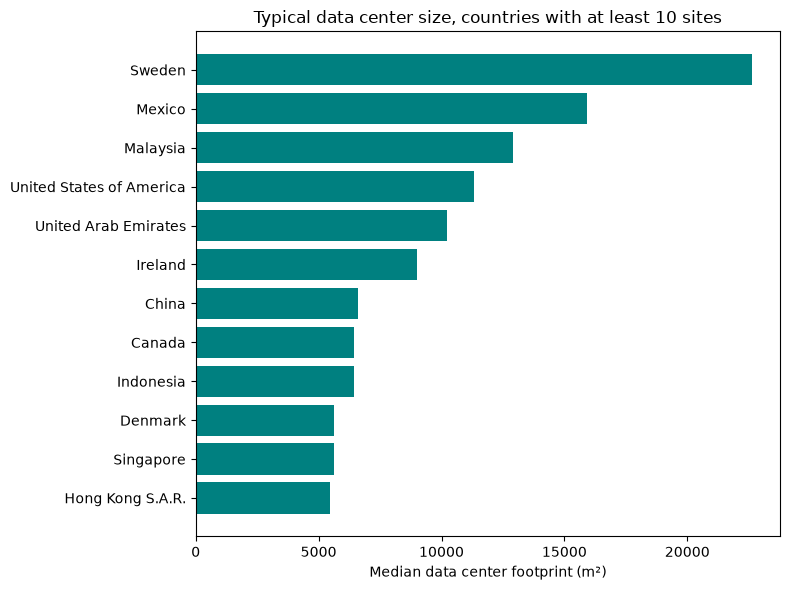

In [6]:
# avg building size per data center
eligible = df[df["osm_facilities"] >= 10]
top = eligible.nlargest(12, "median_footprint_m2").sort_values("median_footprint_m2")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["country"], top["median_footprint_m2"], color="teal")
ax.set_xlabel("Median data center footprint (m²)")
ax.set_title("Typical data center size, countries with at least 10 sites")
plt.tight_layout()
plt.show()

This figure shows the median size of each country's data centers, with Sweden having the largest of any country on Earth. Mexico lags behind, and US falls into 4th.

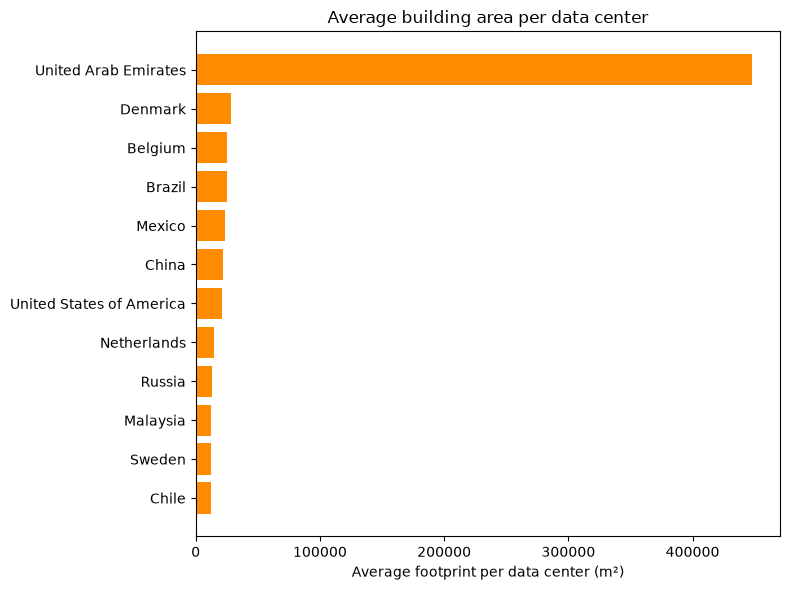

In [7]:
# average building area per data center
top = eligible.nlargest(12, "avg_footprint_m2").sort_values("avg_footprint_m2")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["country"], top["avg_footprint_m2"], color="darkorange")
ax.set_xlabel("Average footprint per data center (m²)")
ax.set_title("Average building area per data center")
plt.tight_layout()
plt.show()

UAE has by far the highest average building area per data center, indicating they build the largest by far. 

**A Plan**

I would expect to see that countries with the largest footprints (size) would also have the largest carbon effect (based on a base rate of intensity, unless we can find a more accurate reading for some of them). We can find this by making a scatterplot of the average size footprint against the carbon emissions. Furthermore, to investigate its relationship to GDP, we could get a scatterplot of log GDP on the X against the log estimated center carbon for each country on the Y. Largest residuals would be interesting to investigate as well. We would want to see how X amount of additional GDP correlates to Y average increase in data center carbon, or the opposite. If my hunch is correct, we would see the latter, because an increased GDP would mean more efficient centers. There could also be confounding variables, and we find that there isn't a correlation at all.

**Krrishh**

**Question 3:**  Do hyperscale data center sites operate on significantly cleaner electrical grids than colocation and telecom facilities when evaluated at the national level?


**Description:** Related to the notion of carbon footprint, certain data centers more efficiently consume energy than others. Hyperscale data centers, which typically are used for industrial-scale computing and cover much larger areas than standard data centers, potentially operate on cleaner grids due to their scale-optimized standards. For each country, we want to determine how these facilities compare to colocation and telecom data centers, which are smaller in scale but might operate less efficiently. 


In [8]:
import seaborn as sns
# load the data 
centers = pd.read_csv("dataset/country_summary.csv")
carbon = pd.read_csv("K Dataset/ember carbon intensity.csv")

# 
kind_columns = {
    "kind_hyperscale": "Hyperscale",
    "kind_colocation": "Colocation",
    "kind_telecom_carrier": "Telecom",
}

long = centers.melt(
    id_vars=["country", "country_iso3"],
    value_vars=kind_columns.keys(),
    var_name="kind",
    value_name="facilities",
)
long["facility_type"] = long["kind"].map(kind_columns)
long = long.merge(
    carbon[["country_iso3", "emissions_intensity_gco2e_per_kwh"]],
    on="country_iso3",
    how="left",
)
long = long[long["facilities"] > 0]

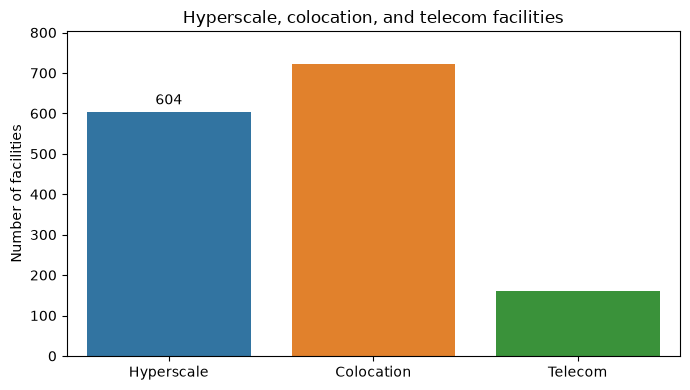

In [9]:
totals = (
    long.groupby("facility_type", as_index=False)["facilities"]
    .sum()
)
order = ["Hyperscale", "Colocation", "Telecom"]

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=totals,
    x="facility_type",
    y="facilities",
    order=order,
    hue="facility_type",
    hue_order=order,
    dodge=False,
    legend=False,
    ax=ax,
)
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlabel("")
ax.set_ylabel("Number of facilities")
ax.set_title("Hyperscale, colocation, and telecom facilities")
ax.set_ylim(0, totals["facilities"].max() + 80)
plt.tight_layout()
plt.show()

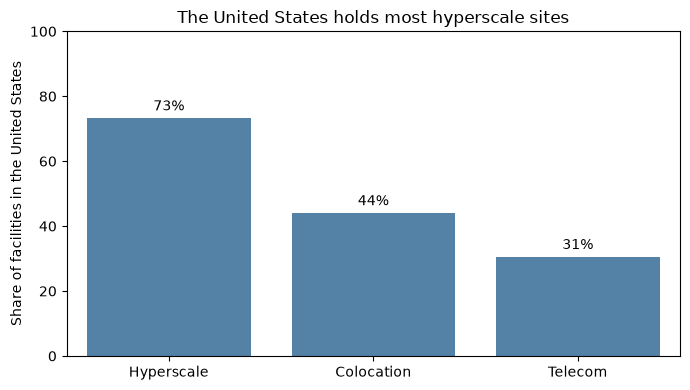

In [10]:
us = (
    long[long["country"] == "United States of America"]
    .groupby("facility_type")["facilities"]
    .sum()
)
total = long.groupby("facility_type")["facilities"].sum()
us_share = (us / total * 100).reindex(order).rename("percent").reset_index()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=us_share,
    x="facility_type",
    y="percent",
    order=order,
    color="steelblue",
    ax=ax,
)
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
ax.set_xlabel("")
ax.set_ylabel("Share of facilities in the United States")
ax.set_title("The United States holds most hyperscale sites")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()


The two figures above are a start, but they do not answer the question yet. The first one counts how many hyperscale, colocation, and telecom facilities are in the data. Colocation is the largest group, then hyperscale, then telecom. That tells us how the sites are split up by type, and it does not say anything about how clean the electricity is where those sites sit. The second figure shows what share of each type is in the United States. Most of the hyperscale sites are there, which is going to matter later, because every one of those sites gets the same US grid number. Even so, that chart is still a count of facilities.

The variable that actually answers the question is 'emissions_intensity_gcole_per_kwh' from the Ember file. It is the grams of COZ-equivalent a country's power plants emit for each kilowatt-hour they generate, and a lower number means a cleaner grid. We compare thatnumber across hyperscale, colocation, and telecom, which come from 'kind_hyperscale, 'kind_colocation" " and 'kind_telecom_carrier." The carbon number is national, so every type in one country shares it. Because of that, we also have to weight by 'facilities', the number of sites of that type in the country. Otherwise a country with one hyperscale site would count the same as a country with several hundred, and the average would not describe where the facilities actually are.

Some of that preparation is already done. 'country_summary.csv' is joined to the Ember table on 'country_iso3", the three type columns are reshaped so each country has a row for each type, and the rows with zero facilities are dropped. What is left is to drop the few rows that do not have an Ember value, and then take a weighted average: intensity times the number of facilities, divided by the total number of facilities of that type.

The figure we expect to end with is a bar chart of that weighted average for the three types, in gC02e/kWh. From there, the regression is a weighted linear regression of emissions intensity on facility type, with each country-type row weighted by how many facilities it has. The coefficients would tell us how much cleaner or dirtier one type's locations are compared with the others. That weighted regression is the step beyond FDS I, since the figures so far only describe counts.

If the hunch is right, hyperscale would have the lowest weighted average, and its coefficient would come out negative compared with colocation and telecom. That would mean hyperscale sites tend to sit in countries with cleaner grids. If the hunch is wrong, the hyperscale average would be about the same as the other two, or higher. That could happen because most hyperscale sites are in the United States, so the US grid number would pull the hyperscale average up even if some of those sites are in cleaner countries. 

In [11]:
!jupyter nbconvert --to html Proposal.ipynb

[NbConvertApp] Converting notebook Proposal.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 513952 bytes to Proposal.html


**Section 1: Data**

This section describes each dataset used in the proposal. It includethe source, how the data were collected, what one row represents, and the key variables. 

**Dataset 1: Data centers by country** (`dataset/country_summary.csv`)

**Source:** OpenStreetMap, https://www.openstreetmap.org. The country table is aggregated from the facility extract in `dataset/data_centers.csv`.

**How it was collected:** OpenStreetMap is a volunteer map. The facility file keeps objects tagged as data centers or related telecom buildings. This table counts those facilities by country and sums their mapped ground area. It is not a government census, so countries that are mapped more thoroughly show more sites.

**One row is:** one country.

**Key variables:**
- `osm_facilities`: number of mapped data-center sites
- `total_footprint_m2`: total mapped ground area, in square meters. This is building size, not carbon emissions
- `median_footprint_m2`: median mapped ground area of the sites in that country
- `kind_hyperscale`, `kind_colocation`, `kind_telecom_carrier`: counts of those facility types
- `country_iso3`: three-letter country code used to join the other tables

In [12]:
import pandas as pd
centers = pd.read_csv("dataset/country_summary.csv")
centers.info()
centers.head()

<class 'pandas.DataFrame'>
RangeIndex: 116 entries, 0 to 115
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   country                    116 non-null    str    
 1   country_iso2               116 non-null    str    
 2   country_iso3               115 non-null    str    
 3   continent                  116 non-null    str    
 4   subregion                  116 non-null    str    
 5   osm_facilities             116 non-null    int64  
 6   with_name                  116 non-null    int64  
 7   with_operator              116 non-null    int64  
 8   with_city                  116 non-null    int64  
 9   with_footprint             116 non-null    int64  
 10  total_footprint_m2         99 non-null     float64
 11  median_footprint_m2        99 non-null     float64
 12  kind_colocation            116 non-null    int64  
 13  kind_financial             116 non-null    int64  
 14  kind_

,country,country_iso2,country_iso3,continent,subregion,osm_facilities,with_name,with_operator,with_city,with_footprint,total_footprint_m2,median_footprint_m2,kind_colocation,kind_financial,kind_government_or_public,kind_hyperscale,kind_research_or_academic,kind_telecom_carrier,kind_unclassified
0,United States of America,US,USA,North America,Northern America,1789,1350,1139,844,1650,37935947.0,11341.0,319,23,0,443,13,49,942
1,France,FR,FRA,Europe,Western Europe,371,287,286,79,278,1591964.0,2061.0,55,3,0,1,10,24,278
2,Germany,DE,DEU,Europe,Western Europe,300,208,184,146,260,1341617.0,2250.0,74,0,0,0,7,12,207
3,United Kingdom,GB,GBR,Europe,Northern Europe,293,241,205,143,264,1819135.0,3855.0,51,4,0,9,3,10,216
4,Netherlands,NL,NLD,Europe,Western Europe,167,114,103,81,98,2405700.0,5380.0,50,0,0,15,0,6,96


**Dataset 2: Grid carbon intensity** (`K Dataset/ember carbon intensity.csv`)

**Source:** Ember yearly electricity data, https://ember-energy.org/data/yearly-electricity-data/

**How it was collected:** Ember compiles electricity generation and power-sector emissions from national statistics and from multi-country sources such as the U.S. Energy Information Administration and Eurostat. This file keeps the 2024 total-generation row for each country. The carbon intensity is a national average, so every facility in a country receives the same value. It does not vary by state or grid region.

**One row is:** one country in 2024.

**Key variables:**
- `emissions_intensity_gco2e_per_kwh`: grams of CO2-equivalent per kilowatt-hour of electricity generated. A lower value is a cleaner grid
- `emissions_mtco2e`: power-sector emissions, in million tonnes of CO2-equivalent
- `generation_twh`: total electricity generated, in terawatt-hours
- `country_iso3`: join key to the data-center table
- `year`: 2024 for every row

In [13]:
carbon = pd.read_csv("K Dataset/ember carbon intensity.csv")
carbon.info()
carbon.head()

<class 'pandas.DataFrame'>
RangeIndex: 194 entries, 0 to 193
Data columns (total 6 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   country                            194 non-null    str    
 1   country_iso3                       194 non-null    str    
 2   year                               194 non-null    int64  
 3   emissions_intensity_gco2e_per_kwh  193 non-null    float64
 4   generation_twh                     194 non-null    float64
 5   emissions_mtco2e                   194 non-null    float64
dtypes: float64(3), int64(1), str(2)
memory usage: 9.2 KB


,country,country_iso3,year,emissions_intensity_gco2e_per_kwh,generation_twh,emissions_mtco2e
0,Afghanistan,AFG,2024,117.172,0.99,0.116
1,Albania,ALB,2024,24.700,8.34,0.206
2,Algeria,DZA,2024,632.846,96.36,60.981
3,American Samoa,ASM,2024,622.222,0.18,0.112
4,Angola,AGO,2024,185.055,15.59,2.885


**Dataset 3: Unemployment rate** (`dataset/disoccupazione.csv`)

**Source:** ILOSTAT, the International Labour Organization's labor statistics database, https://ilostat.ilo.org/data/

**How it was collected:** These are the ILO's annual modelled estimates of the unemployment rate. The rate is the share of the labor force that is unemployed. ILOSTAT publishes it by country, sex, and age group. This file covers 1991 through 2025.

**One row is:** one country, for one sex, one age group, and one year.

**Key variables:**
- `iso_code`: three-letter country code. This matches `country_iso3` in the other tables
- `sex`: `Total`, `Male`, or `Female`
- `age`: `15+`, `15-24`, or `25+`
- `year`: calendar year
- `obs_value`: unemployment rate for that group

In [14]:
unemployment = pd.read_csv("dataset/disoccupazione.csv")
unemployment.info()
unemployment.head()

<class 'pandas.DataFrame'>
RangeIndex: 57519 entries, 0 to 57518
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iso_code   57519 non-null  str    
 1   country    57519 non-null  str    
 2   sex        57519 non-null  str    
 3   age        57519 non-null  str    
 4   year       57519 non-null  int64  
 5   obs_value  57519 non-null  float64
dtypes: float64(1), int64(1), str(4)
memory usage: 2.6 MB


,iso_code,country,sex,age,year,obs_value
0,AFG,Afghanistan,Total,15+,2025,13.351
1,AFG,Afghanistan,Total,15-24,2025,16.785
2,AFG,Afghanistan,Total,25+,2025,11.340
3,AFG,Afghanistan,Male,15+,2025,12.503
4,AFG,Afghanistan,Male,15-24,2025,15.814


**Dataset 4: Employment-to-population ratio** (`dataset/occupazione.csv`)

**Source:** ILOSTAT, https://ilostat.ilo.org/data/

**How it was collected:** This file uses the same ILO modelled-estimate layout as the unemployment file. `obs_value` is the employment-to-population ratio: employed people as a share of the working-age population, by sex and age group, from 1991 through 2025.

**One row is:** one country, for one sex, one age group, and one year.

**Key variables:**
- `iso_code`: three-letter country code
- `sex`: `Total`, `Male`, or `Female`
- `age`: `15+`, `15-24`, or `25+`
- `year`: calendar year
- `obs_value`: employment-to-population ratio for that group

In [15]:
employment = pd.read_csv("dataset/occupazione.csv")
employment.info()
employment.head()

<class 'pandas.DataFrame'>
RangeIndex: 57519 entries, 0 to 57518
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iso_code   57519 non-null  str    
 1   country    57519 non-null  str    
 2   sex        57519 non-null  str    
 3   age        57519 non-null  str    
 4   year       57519 non-null  int64  
 5   obs_value  57519 non-null  float64
dtypes: float64(1), int64(1), str(4)
memory usage: 2.6 MB


,iso_code,country,sex,age,year,obs_value
0,AFG,Afghanistan,Total,15+,2025,32.457
1,AFG,Afghanistan,Total,15-24,2025,31.419
2,AFG,Afghanistan,Total,25+,2025,33.056
3,AFG,Afghanistan,Male,15+,2025,61.038
4,AFG,Afghanistan,Male,15-24,2025,57.355
